# Clustering med KMeans

In [1]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [2]:
df = sns.load_dataset("penguins").dropna()

In [3]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


In [4]:
X = df[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g" ]]
X.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
4,36.7,19.3,193.0,3450.0
5,39.3,20.6,190.0,3650.0


In [5]:
X_scaled = StandardScaler().fit_transform(X)

## KMeans

In [6]:
kmeans = KMeans(n_clusters=3, random_state=42)
df["kluster"] = kmeans.fit_predict(X_scaled)

In [7]:
pd.crosstab(df["species"], df["kluster"])

kluster,0,1,2
species,,,
Adelie,124,0,22
Chinstrap,5,0,63
Gentoo,0,119,0


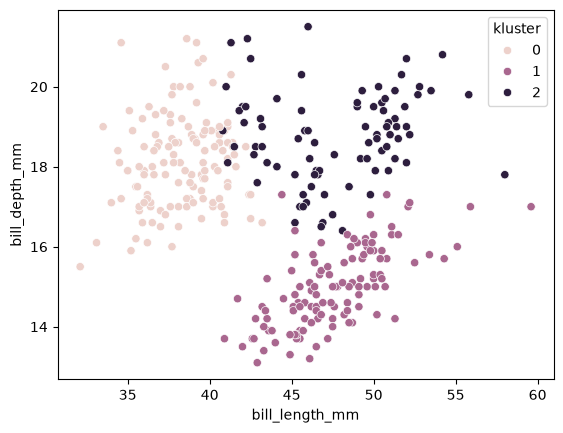

In [8]:
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="kluster");

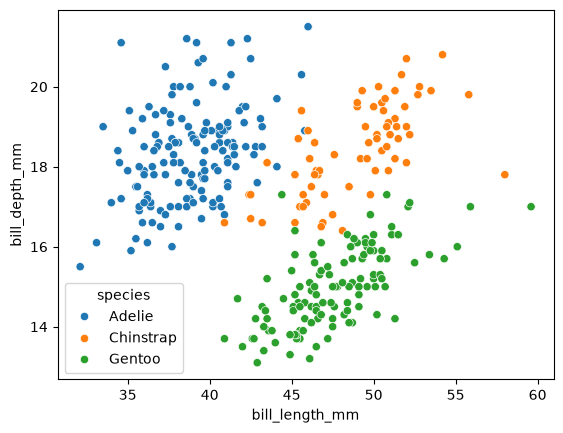

In [9]:
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species");

## Vad händer utan Scaling?

In [10]:
X.std()

bill_length_mm         5.468668
bill_depth_mm          1.969235
flipper_length_mm     14.015765
body_mass_g          805.215802
dtype: float64

In [11]:
df["kluster_unscaled"] = kmeans.fit_predict(X)

In [12]:
pd.crosstab(df["species"], df["kluster_unscaled"])

kluster_unscaled,0,1,2
species,,,
Adelie,94,0,52
Chinstrap,46,0,22
Gentoo,0,80,39


## tolka klustren

In [13]:
df.groupby("kluster")[X.columns].mean()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
kluster,,,,
0,38.276744,18.121705,188.627907,3593.798450
1,47.568067,14.996639,217.235294,5092.436975
2,47.662353,18.748235,196.917647,3898.235294


Kluster 0 - små pingviner med kort och djup näbb och korta fenor
Kluster 1 - Stora pingviner med lång och smal näbb och långa fenor
KLuster 2 - Medelstora pingviner med lång och djup näbb

In [14]:
inertia = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)
    print(k, round(km.inertia_), round(silhouette_score(X_scaled, km.labels_),2))
    

2 553 0.53
3 371 0.45
4 305 0.42
5 229 0.37
6 201 0.37
7 187 0.35
8 167 0.3


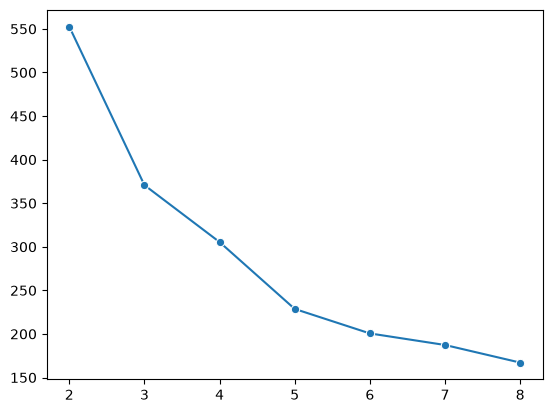

In [15]:
sns.lineplot(x=range(2,9), y=inertia, marker="o");

In [16]:
pd.crosstab([df["species"], df["sex"]], KMeans(n_clusters=6, random_state=42).fit_predict(X_scaled))

col_0              0   1   2   3   4   5
species   sex                           
Adelie    Female  71   0   2   0   0   0
          Male    14   0  57   0   0   2
Chinstrap Female   2   0   0   4   0  28
          Male     0   0   0  31   0   3
Gentoo    Female   0   2   0   0  56   0
          Male     0  52   0   0   9   0

# PCA

In [17]:
df = sns.load_dataset("penguins").dropna()
X = df[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]
X.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
4,36.7,19.3,193.0,3450.0
5,39.3,20.6,190.0,3650.0


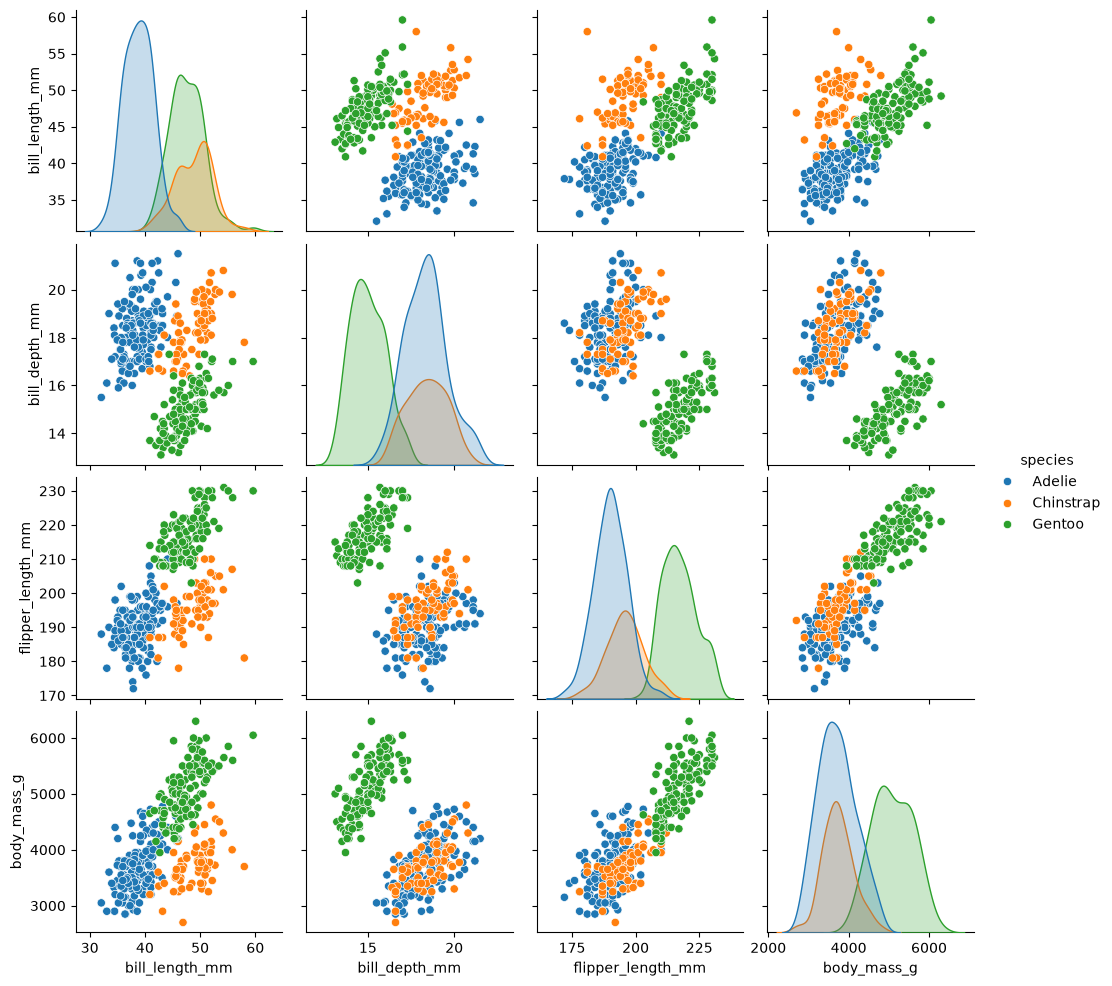

In [18]:
sns.pairplot(df, hue="species")

## Skala och PCA

In [19]:
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [20]:
df["PC1"] = X_pca[:,0]
df["PC2"] = X_pca[:,1]
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,PC1,PC2
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male,-1.853593,0.032069
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female,-1.316254,-0.443527
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female,-1.376605,-0.161230
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female,-1.885288,-0.012351
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male,-1.919981,0.817598


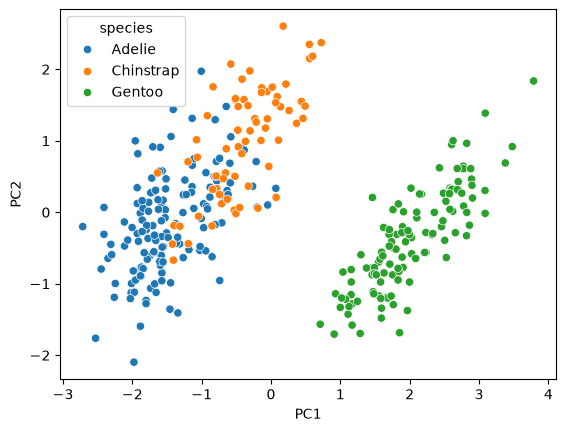

In [21]:
sns.scatterplot(data=df, x="PC1", y="PC2", hue="species");

In [22]:
pca.explained_variance_ratio_

array([0.68633893, 0.19452929])

PC1 fångar 69% av variationen och PC2 19% så tillsammans 88% av variationen i de fyra urspringliga kolumnerna fångas i våra nya 2 kolumner

1. Kör PCA på X utan scaling. Vad blir explained_variance_ratio_? Varför?

2. Rita grafer igen med hue= "sex" och hue="island". Vad ser vi då?

3. Kör KMeans med 3 kluter på X_scaled och rita klustren i samma graf (hue="kluster")

In [23]:
PCA(n_components=2).fit(X).explained_variance_ratio_

array([9.99893229e-01, 7.82232504e-05])

In [24]:
X.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
4,36.7,19.3,193.0,3450.0
5,39.3,20.6,190.0,3650.0


In [25]:
X.std()

bill_length_mm         5.468668
bill_depth_mm          1.969235
flipper_length_mm     14.015765
body_mass_g          805.215802
dtype: float64

In [26]:
kmeans = KMeans(n_clusters=3, random_state=42)
df["kluster"] = kmeans.fit_predict(X_scaled)

In [27]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,PC1,PC2,kluster
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male,-1.853593,0.032069,0
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female,-1.316254,-0.443527,0
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female,-1.376605,-0.161230,0
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female,-1.885288,-0.012351,0
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male,-1.919981,0.817598,0


<Axes: xlabel='PC1', ylabel='PC2'>

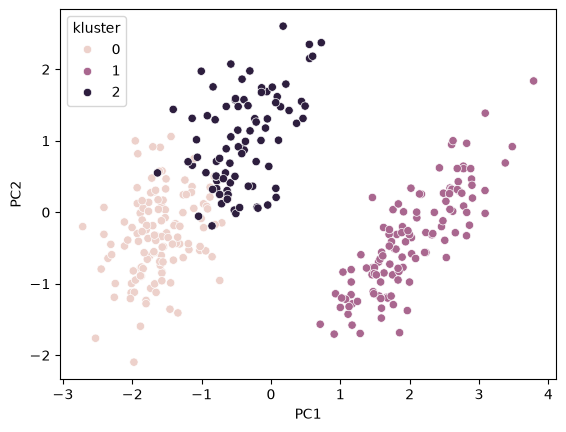

In [28]:
sns.scatterplot(data=df, x="PC1", y="PC2", hue="kluster")